# ДЗ.4 Энергетический отклик детектора
► Промоделировать 1000 событий с энергий 1 МэВ в центре детектора. Построить распределение полного собранного заряда.

► Повторить процедуру для энергий 0.2, 0.5, 0.7, 1.5, 2.0, 3.0 МэВ. Как относительная ширина распределения зависит от энергии?

► Повторить процедуру для источника, смещенного на 1 метр по оси z. Насколько меняется среднее значение для собранного заряда?

In [44]:
import numpy as np

class Detector:
    def __init__(self, R: float, N: int, r: float, a: float):
        self.R = R
        self.N = N
        self.r = r
        self.a = a

    def dots_on_parallels(self):
 # Разместим 40 фотоумножителей на сфере по 5 параллелям по 8 точек (5*8=40) на каждой, выбрав одинаковый шаг по cos(theta), а угол phi делим на 8 равных частей
       
        n_theta = 5
        n_phi = 8

        cos_theta = 1 - 2*(np.arange(n_theta) + 0.5)/n_theta
        theta = np.arccos(cos_theta)
        phi = np.linspace(0, 2*np.pi, n_phi, endpoint=False)

        dots = []

        for i in range(n_theta):
            for j in range(n_phi):
                x = self.R * np.sin(theta[i]) * np.cos(phi[j])
                y = self.R * np.sin(theta[i]) * np.sin(phi[j])
                z = self.R * np.cos(theta[i])

                dots.append([x, y, z])

        self.photocathode_centers = np.array(dots)


    def is_on_photocathode(self, coordinats):
        # Найдем расстояния от заданной точки до центров всех фотокатодов. Если хотя бы одно расстояние меньше радиуса фотокатода, возвращаем True

        lengths = np.linalg.norm(self.photocathode_centers - coordinats, axis=1)

        return np.any(lengths <= self.r)

#НОВАЯ ЧАСТЬ ДЛЯ ЭТОГО ЗАДАНИЯ - ДОБАВИЛА  методы intersection (находим точки пересечения траектории фотона с поверхностью детектора) и photoelectrons (разыгрываем число фотоэлектронов по распределению Пуассона со средним значением a)
    
    def intersection(self, coordinats, direction):
        projection = np.dot(coordinats, direction) # Проекция радиус вектора начальной точки на направление движения фотона

        distance = -projection + np.sqrt(projection**2 + self.R**2 - np.dot(coordinats, coordinats)) 
        # Расстояние от начальной точки до поверхности детектора

        point = coordinats + distance * direction

        return self.is_on_photocathode(point)

    # метод принадлежит Detector, а не Source, тк вероястность выбивания фотоэлектрона "а" уже есть в классе Detector
    def photoelectrons(self):

        return np.random.poisson(self.a)

detector = Detector(R=2.0, N=40, r=0.1, a=0.5)
detector.dots_on_parallels()

In [45]:
import numpy as np

class Source:
    def __init__(self, Y: int):
        self.Y = Y

    def photon_directions(self, E: float):
    
        N = int(self.Y * E) #после вычисления кол-ва фотонов делаем его целым


        phi = np.random.uniform(0, 2*np.pi, N)
        cosTheta = np.random.uniform(-1, 1, N)
        sinTheta = np.sqrt(1 - cosTheta**2)

        x = sinTheta * np.cos(phi)
        y = sinTheta * np.sin(phi)
        z = cosTheta

        return np.array([x, y, z]).T


source = Source(Y=10000)

Разыгрываем число попаданий по биномиальному распределению, а полный заряд по распределению Пуассона (чтобы не генерировать направления фотонов для каждого события)

In [46]:
# вероятность попадания фотона на фотокатод для источника в центре детектора

p = detector.N * detector.r**2 / (4 * detector.R**2)

def gen_charges(E, p):
    #разыгрываем количество попавших фотонов для 1000 событий
    N = int(source.Y * E)
    n = np.random.binomial(N, p, size=1000)

    # разыгрываем полный заряд каждого события
    Q = np.random.poisson(detector.a * n)

    return Q

charges = gen_charges(1.0, p)

print("Средний заряд:", np.mean(charges))
print("Стандартное отклонение:", np.std(charges))


Средний заряд: 125.414
Стандартное отклонение: 13.957958446707025


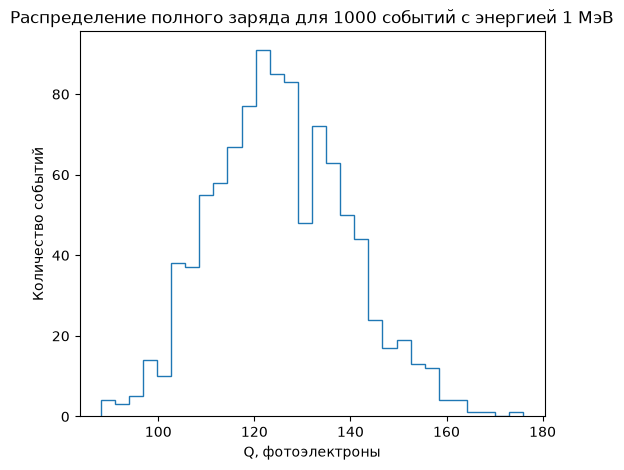

In [47]:
import matplotlib.pyplot as plt

# Распределение полного заряда для 1000 событий с энергией 1 МэВ

plt.figure(figsize=(6, 5))
plt.hist(charges, bins=30, histtype='step')
plt.xlabel('Q, фотоэлектроны')
plt.ylabel('Количество событий')
plt.title('Распределение полного заряда для 1000 событий с энергией 1 МэВ')
plt.show()


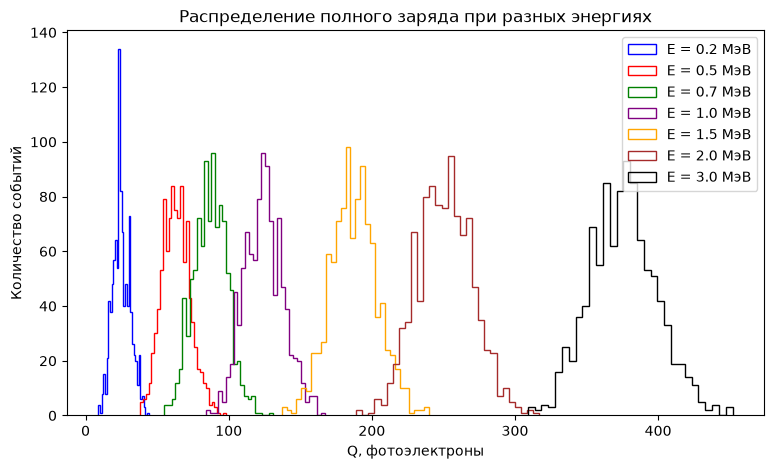

In [48]:
# Моделируем по 1000 событий для разных энергий

energies = [0.2, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0]

relative_widths = []

plt.figure(figsize=(9, 5))
colors = ['blue', 'red', 'green', 'purple', 'orange', 'brown', 'black']
for E, color in zip(energies, colors):
    charges_E = gen_charges(E, p)

    mean = np.mean(charges_E)
    sigma = np.std(charges_E)

    relative_widths.append(sigma / mean)

    plt.hist(charges_E, bins=30, histtype='step', color=color, label=f'E = {E} МэВ')

plt.xlabel('Q, фотоэлектроны')
plt.ylabel('Количество событий')
plt.title('Распределение полного заряда при разных энергиях')
plt.legend()
plt.show()


видно, что с увеличением энергии максимум распределения смещается вправо и абсолютная ширина распределения увеличивается

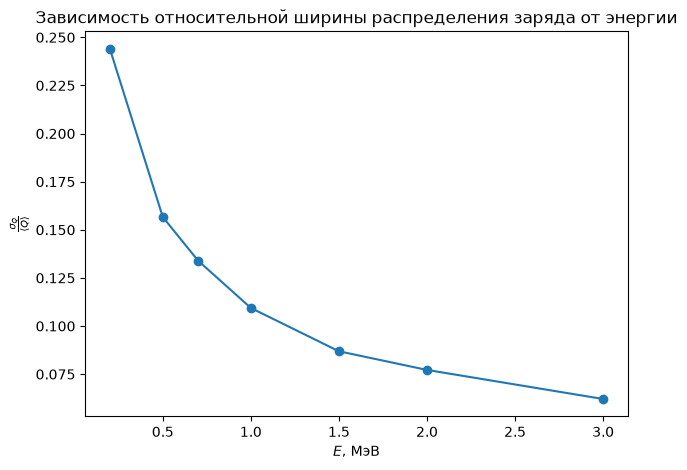

In [49]:
# Зависимость относительной ширины распределения заряда от энергии
plt.figure(figsize=(7, 5))

plt.plot(energies, relative_widths, 'o-')

plt.xlabel(r'$E$, МэВ')
plt.ylabel(r'$\frac{\sigma_Q}{\langle Q\rangle}$')
plt.title('Зависимость относительной ширины распределения заряда от энергии')

plt.show()


При увеличении энергии относительная ширина распределения полного собранного заряда уменьшается приблизительно как (1/\sqrt{E}), тк на большей энергии генерируется больше фотонов и относительные статистические флуктуации заряда становятся меньше.

In [50]:
coordinats = np.array([0, 0, 1]) # Смещаем источник на 1 м по оси z

# Генерируем выборку направлений (200 000 случайных направлений)
directions = source.photon_directions(E=20.0)

# Находим точки пересечения траекторий с поверхностью детектора
projection = np.dot(directions, coordinats)

distance = -projection + np.sqrt(projection**2 + detector.R**2 - np.dot(coordinats, coordinats))

points = coordinats + distance[:, None] * directions

# Проверка попадание на фотокатоды
products = np.dot(points, detector.photocathode_centers.T)

hits = np.any(
    products >= detector.R**2 - detector.r**2 / 2,
    axis=1
)

p_shifted = np.mean(hits)

print("Вероятность попадания из центра:", p)
print("Вероятность попадания после смещения:", p_shifted)


Вероятность попадания из центра: 0.025000000000000005
Вероятность попадания после смещения: 0.024365


In [51]:
# смоделируем 1000 событий с энергией 1 МэВ для смещённого источника

charges_shifted = gen_charges(1.0, p_shifted)

mean_center = np.mean(charges)
mean_shifted = np.mean(charges_shifted)

change = (mean_shifted - mean_center) / mean_center * 100

print("Средний заряд для источника в центре:", mean_center)
print("Средний заряд для смещённого источника:", mean_shifted)
print("Относительное изменение:", round(change, 2),"%")


Средний заряд для источника в центре: 125.414
Средний заряд для смещённого источника: 122.917
Относительное изменение: -1.99 %


получилось, что при смещении источника на 1 м вдоль оси z вероятность попадания фотона на фотокатод уменьшилась (в данной генерации с 0.025 до 0.024365). Средний собранный заряд уменьшился с 125.414 до 122.917 фотоэлектрона, то есть примерно на 2% -> смещение источника приводит к небольшому изменению среднего заряда, тк с изменилась вероятность попадания фотонов на фотокатоды (из-за смещения источника относительно центра детектора). Таким образом, средний собранный заряд зависит от положения источника внутри детектора.